SANTIAGO DIE MOREJÓN - 22/03/2026 - IA - Entregable 1 - Comparativa de Clasificadores

# Notebook 3: Comparativa de Clasificadores
En los notebooks anteriores concluimos que las clases no son linealmente separables y que será necesario un clasificador capaz de capturar relaciones no lineales.

En este notebook compararemos los algoritmos de clasificación vistos en las prácticas 5 y 6 con dos configuraciones de descriptores (3 y 5) para seleccionar el mejor modelo para el envío a Kaggle.

## 1. Carga de datos

Comenzamos importando las librerías necesarias y cargando los datos desde el repositorio DATA_URL.

In [115]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
%config InlineBackend.figure_format = 'svg'

In [116]:
!wget DATA_URL -O train.csv
!wget DATA_URL  -O test.csv

--2026-03-22 15:31:17--  DATA_URL
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 336082 (328K) [text/plain]
Saving to: ‘train.csv’

train.csv           100%[===================>] 328.21K  --.-KB/s    in 0.08s   

2026-03-22 15:31:18 (4.12 MB/s) - ‘train.csv’ saved [336082/336082]

--2026-03-22 15:31:18--  DATA_URL
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.110.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 113736 (111K) [text/plain]
Saving to: ‘test.csv’

test.csv            100%[===================>] 111.07K  --.-KB/s    in 0.04s   

2026-03-22 15:31:18 (2.91 MB/s) - ‘test.

In [117]:
traindf = pd.read_csv('train.csv')
testdf  = pd.read_csv('test.csv')
traindf.head()

,SL,EEG,BP,HR,CIRCULATION,ACTIVITY
0,4019.64,-1600.00,13,79,317,3
1,2191.03,-1146.08,20,54,165,2
2,2787.99,-1263.38,46,67,224,2
3,9545.98,-2848.93,26,138,554,4
4,14148.80,-2381.15,85,120,809,4


## 2. Preparación de los datos

Antes de entrenar cualquier modelo necesitamos aplicar las transformaciones que justificamos en los notebooks anteriores.

### 2.1 Transformación logarítmica

Las variables SL y CIRCULATION contienen valores extremadamente altos con colas largas a la derecha, como ya vimos en los boxplots y gráficos de densidad del notebook 2. Para comprimir estos valores extremos y estabilizar las distribuciones, aplicamos una transformación logarítmica `log1p`.

In [118]:
traindf['SL']= np.log1p(traindf['SL'])
traindf['CIRCULATION']= np.log1p(traindf['CIRCULATION'])
testdf['SL']= np.log1p(testdf['SL'])
testdf['CIRCULATION'] = np.log1p(testdf['CIRCULATION'])

### 2.2 Configuraciones de descriptores

Vamos a comparar los modelos con dos conjuntos de descriptores:

* 3 descriptores (`BP`, `HR`, `CIRCULATION`): eliminamos `EEG` (inútil ) y `SL` (correlación 0.98 con CIRCULATIONpor lo que  es redundante).
* 5 descriptores: para comprobar si incluir los redundantes mejora o empeora el rendimiento.

In [119]:
cols_3 = ['BP', 'HR', 'CIRCULATION']
cols_5 = ['SL', 'EEG', 'BP', 'HR', 'CIRCULATION']

### 2.3 Separación y escalado

Separamos en train/test con un 25% para test. Luego escalamos con `StandardScaler` para los modelos sensibles a la escala (KNN, SVM, Perceptrón, MLP, LR). Los árboles de decisión y Random Forest no necesitan escalado.

In [120]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [121]:
y = traindf['ACTIVITY'].values

**3 descriptores**

In [122]:
X3 = traindf[cols_3].values
X3_train, X3_test, y_train, y_test = train_test_split(X3, y, test_size=0.25, random_state=42,stratify=y)

scaler3 = StandardScaler()
X3_train_sc = scaler3.fit_transform(X3_train)
X3_test_sc  = scaler3.transform(X3_test)

**5 descriptores**

In [123]:
X5 = traindf[cols_5].values
X5_train, X5_test, _, _ = train_test_split(X5, y, test_size=0.25, random_state=42,stratify=y)

scaler5 = StandardScaler()
X5_train_sc = scaler5.fit_transform(X5_train)
X5_test_sc  = scaler5.transform(X5_test)

In [124]:
print(X3_train.shape[0])
print(X3_test.shape[0])

8999
3000


## 3. Función de evaluación

Definimos una función `evalua` que recibe un modelo ya entrenado y devuelve su accuracy sobre el conjunto de test.

In [125]:
from sklearn.metrics import accuracy_score

def evalua(model, X_test, y_test):
    predicciones = model.predict(X_test)
    return accuracy_score(y_test, predicciones)

## 4. Entrenamiento y comparativa de clasificadores

Vamos a entrenar todos los clasificadores vistos en las prácticas 5 y 6 con sus parámetros por defecto, sin optimización de hiperparámetros. Esto nos permite hacer una comparativa  del rendimiento de cada algoritmo normal.

Para cada modelo entrenamos dos versiones: una con 3 descriptores y otra con 5.

In [126]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import Perceptron
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

In [127]:
resultados_3 = {}
resultados_5 = {}

### 4.1 Regresión Logística (línea base lineal)

Incluyo este clasificador lineal únicamente para probar las conclusiones del notebook 2, que es que funcione peor que los modelos no lineales.

In [128]:
modelLR = LogisticRegression(max_iter=1000, random_state=42)

In [129]:
modelLR.fit(X3_train_sc, y_train)
resultados_3['Regresión Logística'] = evalua(modelLR, X3_test_sc, y_test)
print(f'Regresión Logística (3 desc): {resultados_3["Regresión Logística"]:.4f}')

Regresión Logística (3 desc): 0.3043


In [130]:
modelLR.fit(X5_train_sc, y_train)
resultados_5['Regresión Logística'] = evalua(modelLR, X5_test_sc, y_test)
print(f'Regresión Logística (5 desc): {resultados_5["Regresión Logística"]:.4f}')

Regresión Logística (5 desc): 0.3133


### 4.2 K-Nearest Neighbors (KNN)

KNN es sensible a la escala, por lo que usamos los datos escalados.

In [131]:
modelKNN = KNeighborsClassifier(n_neighbors=5)

In [132]:
modelKNN.fit(X3_train_sc, y_train)
resultados_3['KNN (k=5)'] = evalua(modelKNN, X3_test_sc, y_test)
print(f'KNN k=5 (3 desc): {resultados_3["KNN (k=5)"]:.4f}')

KNN k=5 (3 desc): 0.6177


In [133]:
modelKNN.fit(X5_train_sc, y_train)
resultados_5['KNN (k=5)'] = evalua(modelKNN, X5_test_sc, y_test)
print(f'KNN k=5 (5 desc): {resultados_5["KNN (k=5)"]:.4f}')

KNN k=5 (5 desc): 0.6360


### 4.3 SVM Lineal

Al ser lineal, se espera un comportamiento parecido a la Regresión Logística.

In [134]:
modelSVML = SVC(kernel='linear', random_state=42)

In [135]:
modelSVML.fit(X3_train_sc, y_train)
resultados_3['SVM Lineal'] = evalua(modelSVML, X3_test_sc, y_test)
print(f'SVM Lineal (3 desc): {resultados_3["SVM Lineal"]:.4f}')

SVM Lineal (3 desc): 0.2813


In [136]:
modelSVML.fit(X5_train_sc, y_train)
resultados_5['SVM Lineal'] = evalua(modelSVML, X5_test_sc, y_test)
print(f'SVM Lineal (5 desc): {resultados_5["SVM Lineal"]:.4f}')

SVM Lineal (5 desc): 0.3017


### 4.4 SVM Sigmoide

Usamos los mismos hiperparámetros que en la práctica 5 (gamma=2, coef0=1).

In [137]:
modelSVMS = SVC(kernel='sigmoid', gamma=2, coef0=1, random_state=42)

In [138]:
modelSVMS.fit(X3_train_sc, y_train)
resultados_3['SVM Sigmoide'] = evalua(modelSVMS, X3_test_sc, y_test)
print(f'SVM Sigmoide (3 desc): {resultados_3["SVM Sigmoide"]:.4f}')

SVM Sigmoide (3 desc): 0.1863


In [139]:
modelSVMS.fit(X5_train_sc, y_train)
resultados_5['SVM Sigmoide'] = evalua(modelSVMS, X5_test_sc, y_test)
print(f'SVM Sigmoide (5 desc): {resultados_5["SVM Sigmoide"]:.4f}')

SVM Sigmoide (5 desc): 0.1740


### 4.5 Perceptrón

El Perceptrón es la red neuronal más sencilla y es un clasificador lineal, por lo que esperamos resultados similares a la Regresión Logística.

In [140]:
modelPerc = Perceptron(eta0=1.0, max_iter=100, random_state=42)

In [141]:
modelPerc.fit(X3_train_sc, y_train)
resultados_3['Perceptrón'] = evalua(modelPerc, X3_test_sc, y_test)
print(f'Perceptrón (3 desc): {resultados_3["Perceptrón"]:.4f}')

Perceptrón (3 desc): 0.2663


In [142]:
modelPerc.fit(X5_train_sc, y_train)
resultados_5['Perceptrón'] = evalua(modelPerc, X5_test_sc, y_test)
print(f'Perceptrón (5 desc): {resultados_5["Perceptrón"]:.4f}')

Perceptrón (5 desc): 0.2257


### 4.6 Árbol de Decisión

Los árboles de decisión son modelos no lineales que no son sensibles a la escala, por lo que los entrenamos con los datos sin escalar.

In [143]:
modelTree = DecisionTreeClassifier(random_state=42)

In [144]:
modelTree.fit(X3_train, y_train)
resultados_3['Árbol de Decisión'] = evalua(modelTree, X3_test, y_test)
print(f'Árbol de Decisión (3 desc): {resultados_3["Árbol de Decisión"]:.4f}')

Árbol de Decisión (3 desc): 0.6837


In [145]:
modelTree.fit(X5_train, y_train)
resultados_5['Árbol de Decisión'] = evalua(modelTree, X5_test, y_test)
print(f'Árbol de Decisión (5 desc): {resultados_5["Árbol de Decisión"]:.4f}')

Árbol de Decisión (5 desc): 0.6800


### 4.7 Random Forest

Random Forest es un ensemble de árboles de decisión. Suele mejorar al árbol individual al reducir el sobreajuste mediante el promedio de múltiples árboles entrenados con subconjuntos aleatorios de datos y descriptores. Tampoco necesita escalado.Este modelo no lo trabajamos tanto pero aparece en el adicional 1 de la practica 6.

In [146]:
modelRF = RandomForestClassifier(n_estimators=100, random_state=42)

In [147]:
modelRF.fit(X3_train, y_train)
resultados_3['Random Forest'] = evalua(modelRF, X3_test, y_test)
print(f'Random Forest (3 desc): {resultados_3["Random Forest"]:.4f}')

Random Forest (3 desc): 0.6900


In [148]:
modelRF.fit(X5_train, y_train)
resultados_5['Random Forest'] = evalua(modelRF, X5_test, y_test)
print(f'Random Forest (5 desc): {resultados_5["Random Forest"]:.4f}')

Random Forest (5 desc): 0.7467


### 4.8 Red Neuronal (MLP)

El Perceptrón Multicapa es un clasificador no lineal y es sensible a la escala. Usamos dos capas ocultas de 100 neuronas cada una.

In [149]:
modelMLP = MLPClassifier(hidden_layer_sizes=(100, 100), max_iter=500, random_state=42)

In [150]:
modelMLP.fit(X3_train_sc, y_train)
resultados_3['MLP'] = evalua(modelMLP, X3_test_sc, y_test)
print(f'MLP (3 desc): {resultados_3["MLP"]:.4f}')

MLP (3 desc): 0.5817


In [151]:
modelMLP.fit(X5_train_sc, y_train)
resultados_5['MLP'] = evalua(modelMLP, X5_test_sc, y_test)
print(f'MLP (5 desc): {resultados_5["MLP"]:.4f}')

MLP (5 desc): 0.6053


## 5. Resumen de resultados

Reunimos todos los resultados en una tabla y los visualizamos en un gráfico de barras para facilitar la comparación.

In [152]:
resdf = pd.DataFrame({'3 descriptores': resultados_3,'5 descriptores': resultados_5})
resdf = resdf.sort_values('5 descriptores', ascending=False)
print(resdf.to_string())

                     3 descriptores  5 descriptores
Random Forest              0.690000        0.746667
Árbol de Decisión          0.683667        0.680000
KNN (k=5)                  0.617667        0.636000
MLP                        0.581667        0.605333
Regresión Logística        0.304333        0.313333
SVM Lineal                 0.281333        0.301667
Perceptrón                 0.266333        0.225667
SVM Sigmoide               0.186333        0.174000


## 6. Visualización de resultados

Visualizamos los resultados en un gráfico de barras agrupadas para comparar el rendimiento de cada modelo con 3 y 5 descriptores.

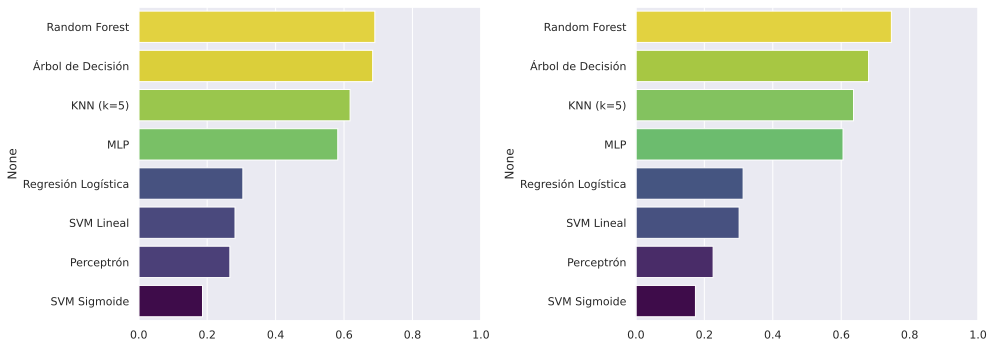

In [153]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

res3 = pd.Series(resultados_3).sort_values(ascending=False)
sns.barplot(x=res3.values, hue=res3.values, y=res3.index, ax=axes[0], palette='viridis', legend=False)
axes[0].set_xlim(0, 1)

res5 = pd.Series(resultados_5).sort_values(ascending=False)
sns.barplot(x=res5.values, hue=res5.values, y=res5.index, ax=axes[1], palette='viridis', legend=False)
axes[1].set_xlim(0, 1)

plt.tight_layout()

## 7. Análisis de resultados

De primeras no use stratify, pero tras añadir stratify=y al split para respetar la proporción de clases, los resultados bajan ligeramente.Random forest de 0.751 a 0.747 pero es una prediccion mas fiable.

Los tres clasificadores lineales (Regresión Logística, SVM Lineal  y Perceptrón ) obtienen accuracies por debajo de 0.32 con 5 descriptores, mientras que los modelos no lineales superan todos el 0.60.

El caso del SVM Sigmoide (0.200) es especial. Aunque es no lineal, los hiperparámetros que usamos (gamma=2, coef0=1) son los mismos de la práctica 5, que se definieron para un dataset  diferente.

La mayoría de modelos mejoran cuando pasamos de 3 a 5 descriptores, las únicas excepciones son el Árbol de Decisión  y SVM Lineal . La mejora más importante es la de Random Forest, que sube de 0.69 a 0.746 y es claramente el mejor clasificador.

## 8. Conclusión

En este notebook hemos comparado 8 clasificadores con dos configuraciones de descriptores. Los resultados principales son:

* Se confirma la conclusion a la que llegamos en el notebook anterior. Los tres clasificadores lineales (LR, SVM Lineal y Perceptrón) rinden por debajo de 0.32, mientras que los no lineales superan el 0.60. Las clases no son linealmente separables.

* Usar 5 descriptores es mejor que usar 3 para la mayoría de modelos. Aunque SL es redundante con CIRCULATION (correlación 0.98) y EEG es inútil, Random Forest sabe aprovechar la información extra gracias a su selección aleatoria de descriptores.

* Random Forest es el mejor modelo con una accuracy de 0.746, superando al Árbol de Decisión individual y al KNN.

Para el notebook de envío a Kaggle, parece que el modelo a seleccionar es el Random Forest con los 5 descriptores. Pero en el siguiente notebook optimizaremos los hiperparametros de los modelos no lineales para ver si sigue siendo la mejor opcion o existe otra.